**파일업로드**

In [1]:
from google.colab import files
uploaded = files.upload()

Saving 101_DT_1IN1503_20260914162447.xls to 101_DT_1IN1503_20260914162447.xls
Saving 장애유형별_장애인_성_시군구별__20260921132958.xlsx to 장애유형별_장애인_성_시군구별__20260921132958.xlsx
Saving 한국사회보장정보원_복지사업 시군구별 수급권자 현황_20251231.csv to 한국사회보장정보원_복지사업 시군구별 수급권자 현황_20251231.csv


**한글 폰트 설정**

In [2]:
!apt-get -qq install fonts-nanum > /dev/null
import matplotlib.font_manager as fm
fontpath = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
fm.fontManager.addfont(fontpath)
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

import pandas as pd
import numpy as np
import xml.etree.ElementTree as ET

**시도/시군구 이름 표준화**

In [4]:
SIDO_NAMES = {
    '서울특별시','부산광역시','대구광역시','인천광역시','광주광역시','대전광역시','울산광역시',
    '세종특별자치시','경기도','강원특별자치도','충청북도','충청남도','전북특별자치도',
    '전라남도','경상북도','경상남도','제주특별자치도'
}
SIDO_ALIASES = {'강원도':'강원특별자치도','전라북도':'전북특별자치도'}
NON_REGION = {'전국','동부','읍부','면부'}
GU_HAVING_CITIES = {'수원시','성남시','안양시','안산시','고양시','용인시',
                     '청주시','천안시','전주시','포항시','창원시','부천시'}

def canonical_key(sido, sigungu):
    """3개 데이터셋 모두에서 동일하게 사용할 최종 조인 키.
       세종은 '시도=시군구'가 같은 특수 케이스라 '세종특별자치시' 하나로 고정."""
    if sido is None:
        return None
    if '세종' in sido:
        return '세종특별자치시'
    return f"{sido} {sigungu}"

**고령인구비율**

In [5]:
# ============================================================
# 1) 고령인구 파일 (KOSIS, XML 위장 .xls, 읍면동 단위 원자료)
# ============================================================
def read_kosis_xml_xls(path):
    """KOSIS에서 받은 '.xls'가 실제로는 SpreadsheetML(엑셀 XML) 포맷이라
       pandas.read_excel로 못 엶 -> 직접 XML 파싱"""
    with open(path, 'rb') as f:
        raw = f.read()
    text = raw.decode('euc-kr', errors='replace').lstrip()
    text = text.replace('encoding="EUC-KR"', 'encoding="UTF-8"')
    # '메타정보' 시트에 이스케이프 안 된 '<' 문자가 있어 전체 파싱시 에러남 -> 데이터 시트까지만 자름
    idx = text.find('메타정보')
    if idx != -1:
        idx2 = text.rfind('<Worksheet', 0, idx)
        text = text[:idx2] + '</Workbook>'
    root = ET.fromstring(text)
    ns = '{urn:schemas-microsoft-com:office:spreadsheet}'
    rows_out = []
    for ws in root.findall(f'{ns}Worksheet'):
        table = ws.find(f'{ns}Table')
        if table is None:
            continue
        for row in table.findall(f'{ns}Row'):
            cells = []
            for cell in row.findall(f'{ns}Cell'):
                data = cell.find(f'{ns}Data')
                cells.append(data.text if data is not None else None)
            rows_out.append(cells)
    return rows_out


def build_sigungu_keys(raw_names):
    """KOSIS 형식: 한 열에 전국/동부·읍부·면부/시도/시군구/읍면동이 순서대로
       평평하게(계층 구분 없이) 나열되어 있음.
       ※ 동부/읍부/면부는 전국 밑뿐 아니라 각 시도 밑에도 반복 등장하므로,
          이걸 만나도 cur_sido를 리셋하지 않아야 함."""
    keys = []
    cur_sido = None
    skip_sub_gu = False
    for raw in raw_names:
        if pd.isna(raw):
            keys.append(None); continue
        name = str(raw).strip()
        if name in NON_REGION:
            keys.append(None); continue          # cur_sido는 유지
        canon = SIDO_ALIASES.get(name, name)
        if canon in SIDO_NAMES:
            cur_sido, skip_sub_gu = canon, False
            keys.append(None); continue           # 시도 총계행 자체는 제외
        if skip_sub_gu and name.endswith('구'):
            keys.append(None); continue           # 특례시 하위 구 -> 제외(중복 방지)
        skip_sub_gu = False
        if name.endswith(('시', '군', '구')):
            if name in GU_HAVING_CITIES:
                skip_sub_gu = True
            keys.append(canonical_key(cur_sido, name) if cur_sido else None)
            continue
        keys.append(None)                          # 읍면동 이하 상세행 -> 제외
    return keys


def load_age_sigungu(path):
    raw_rows = read_kosis_xml_xls(path)
    data_rows = [r for r in raw_rows[2:] if r and len(r) >= 5]
    long_df = pd.DataFrame(data_rows, columns=['행정구역_raw', '연령별', '항목', '단위', '2025'])
    long_df['2025'] = pd.to_numeric(long_df['2025'], errors='coerce')
    long_df['sigungu'] = build_sigungu_keys(long_df['행정구역_raw'])
    long_valid = long_df[long_df['sigungu'].notna()].copy()

    total_pop = (long_valid[(long_valid['연령별'] == '합계') & (long_valid['항목'] == '총인구(명)')]
                 .groupby('sigungu')['2025'].sum().reset_index(name='전체인구'))
    # KOSIS가 '65세이상' 합계를 이미 별도 행으로 제공하므로 직접 더할 필요 없음
    elderly = (long_valid[(long_valid['연령별'] == '65세이상') & (long_valid['항목'] == '총인구(명)')]
               .groupby('sigungu')['2025'].sum().reset_index(name='고령인구'))

    age_sigungu = total_pop.merge(elderly, on='sigungu', how='left')
    age_sigungu['고령인구비율'] = age_sigungu['고령인구'] / age_sigungu['전체인구']
    return age_sigungu

age_sigungu = load_age_sigungu(list(uploaded.keys())[0])  # 101_DT_1IN1503_....xls
print(age_sigungu.shape)          # (229, 4) 나와야 정상
print('전체인구 합:', age_sigungu['전체인구'].sum())   # 51,817,499 나와야 정상
age_sigungu.head()

(229, 4)
전체인구 합: 51817499.0


,sigungu,전체인구,고령인구,고령인구비율
0,강원특별자치도 강릉시,211628.0,56024.0,0.264729
1,강원특별자치도 고성군,27706.0,9051.0,0.326680
2,강원특별자치도 동해시,84564.0,22614.0,0.267419
3,강원특별자치도 삼척시,62105.0,18814.0,0.302939
4,강원특별자치도 속초시,78972.0,20190.0,0.255660


**장애인 인구 비율**

In [6]:
# ============================================================
# 2) 장애인 파일 (GSIS, 시군구 단위, 들여쓰기로 시도-시군구 계층 표시)
# ============================================================
GSIS_SIDO_PREFIX_MAP = {
    '부산': '부산광역시', '대구': '대구광역시', '인천': '인천광역시',
    '광주': '광주광역시', '대전': '대전광역시', '울산': '울산광역시',
    '경남': '경상남도',
}

def parse_gsis_region(raw_name, cur_sido):
    """GSIS 표시명 하나를 (갱신된 cur_sido, 시군구 key)로 변환.
       - 들여쓰기 없는 이름  -> 시도 헤더행
       - 들여쓰기 있는 이름  -> 시군구행 (동명이인 방지용 '시도약칭-' 접두어 제거,
         예: '부산-중구' -> '중구', '경남-고성군' -> '고성군')
       - '통합창원시'        -> '창원시'로 정규화 (이 파일은 창원시를 구 분리 없이 통합 표기)"""
    if raw_name is None:
        return cur_sido, None
    raw = str(raw_name)
    stripped = raw.strip()
    if stripped == '':
        return cur_sido, None
    is_indented = raw != stripped
    name = stripped
    if not is_indented:
        canon = SIDO_ALIASES.get(name, name)
        if canon in SIDO_NAMES:
            return canon, None
        return cur_sido, None
    for prefix, full_sido in GSIS_SIDO_PREFIX_MAP.items():
        if name.startswith(prefix + '-'):
            name = name[len(prefix) + 1:]
            break
    if name == '통합창원시':
        name = '창원시'
    return cur_sido, canonical_key(cur_sido, name)


def load_disability_sigungu(path):
    import openpyxl
    wb = openpyxl.load_workbook(path, data_only=True)
    ws = wb['데이터']
    rows = list(ws.iter_rows(values_only=True))
    data_rows = rows[2:]  # 상위 2행은 헤더

    keys, total_disabled = [], []
    cur_sido, cur_key = None, None
    for r in data_rows:
        region_raw, item, total_col = r[0], r[1], r[2]
        if region_raw is not None and str(region_raw).strip() != '':
            cur_sido, cur_key = parse_gsis_region(region_raw, cur_sido)
        if cur_key is None:
            continue
        if item == '총계':          # 지체/시각/청각 등 유형별 중복 없이 '총계' 행만 사용
            keys.append(cur_key)
            total_disabled.append(total_col)

    disability_sigungu = pd.DataFrame({'sigungu': keys, '장애인수': total_disabled})
    disability_sigungu['장애인수'] = pd.to_numeric(disability_sigungu['장애인수'], errors='coerce')
    disability_sigungu = disability_sigungu.groupby('sigungu', as_index=False)['장애인수'].sum()
    return disability_sigungu

disability_sigungu = load_disability_sigungu(list(uploaded.keys())[1])  # 장애유형별_..._시군구별.xlsx
print(disability_sigungu.shape)          # (229, 2) 나와야 정상
print('장애인수 합:', disability_sigungu['장애인수'].sum())   # 2,627,761 나와야 정상
disability_sigungu.head()

/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


(229, 2)
장애인수 합: 2627761.0


,sigungu,장애인수
0,강원특별자치도 강릉시,13206.0
1,강원특별자치도 고성군,2189.0
2,강원특별자치도 동해시,6460.0
3,강원특별자치도 삼척시,5204.0
4,강원특별자치도 속초시,4694.0


**기초생활수급자 비율**

In [7]:
# ============================================================
# 3) 기초생활수급자 CSV (시도/시군구 분리 컬럼, 특례시=구 합산 필요)
# ============================================================
def load_welfare_sigungu(path):
    for enc in ['utf-8-sig', 'cp949', 'euc-kr']:
        try:
            df = pd.read_csv(path, encoding=enc)
            break
        except UnicodeDecodeError:
            continue

    # 기초생계/의료/주거/교육급여는 서로 중복(한 수급자가 여러 급여를 동시 수급) 되므로
    # 합산하지 않고, 헤드라인 집계 항목인 '기초생활보장(맞춤형급여)' 하나만 사용
    target = df[df['사업명'] == '기초생활보장(맞춤형급여)'].copy()

    def normalize_city(sigungu):
        """이 CSV는 KOSIS와 반대로 특례시 합계 행이 '잔여치'이고,
           시 전체 합계를 구하려면 시 행 + 하위 구 행들을 모두 더해야 함
           (예: 창원시 146 + 창원시의창구 12029 + ... = 창원시 전체 53,779).
           -> 시-구 이름을 전부 상위 '시' 이름으로 묶은 뒤 groupby에서 합산."""
        s = str(sigungu).strip()
        for city in GU_HAVING_CITIES:
            if s.startswith(city):
                return city
        return s

    target['sido_norm'] = target['시도'].apply(lambda x: SIDO_ALIASES.get(str(x).strip(), str(x).strip()))
    target['sigungu_norm'] = target['시군구'].apply(normalize_city)
    target['sigungu'] = target.apply(lambda r: canonical_key(r['sido_norm'], r['sigungu_norm']), axis=1)

    welfare_sigungu = (target.groupby('sigungu', as_index=False)
                        .agg(기초생활수급자수=('수급권자수', 'sum')))
    return welfare_sigungu

welfare_sigungu = load_welfare_sigungu(list(uploaded.keys())[2])  # ...수급권자_현황....csv
print(welfare_sigungu.shape)   # (229, 2) 나와야 정상
welfare_sigungu.head()

(229, 2)


,sigungu,기초생활수급자수
0,강원특별자치도 강릉시,14236
1,강원특별자치도 고성군,1631
2,강원특별자치도 동해시,6114
3,강원특별자치도 삼척시,4431
4,강원특별자치도 속초시,6167


**3개 데이터 병합 + 비율 계산**

In [8]:
# 시군구 키 기준으로 3개 데이터셋 병합 (교차검증: 아래에서 불일치 지역이 있는지 확인)
age_keys = set(age_sigungu['sigungu'])
dis_keys = set(disability_sigungu['sigungu'])
wel_keys = set(welfare_sigungu['sigungu'])
print('고령-장애인 불일치:', (age_keys - dis_keys) | (dis_keys - age_keys))
print('고령-수급자 불일치:', (age_keys - wel_keys) | (wel_keys - age_keys))
# -> 둘 다 빈 set()이 나와야 정상 (229개 지역 완전 일치)

merged = (age_sigungu
          .merge(disability_sigungu, on='sigungu', how='inner')
          .merge(welfare_sigungu, on='sigungu', how='inner'))

merged['장애인인구비율'] = merged['장애인수'] / merged['전체인구']
merged['기초생활수급자비율'] = merged['기초생활수급자수'] / merged['전체인구']

merged[['시도', '시군구']] = merged['sigungu'].str.split(' ', n=1, expand=True)
merged.loc[merged['sigungu'] == '세종특별자치시', ['시도', '시군구']] = ['세종특별자치시', '세종특별자치시']

print(merged.shape)  # (229, 10)
merged.to_csv('인구특성_시군구_2025.csv', index=False, encoding='utf-8-sig')
merged.describe()

고령-장애인 불일치: set()
고령-수급자 불일치: set()
(229, 10)


,전체인구,고령인구,고령인구비율,장애인수,기초생활수급자수,장애인인구비율,기초생활수급자비율
count,2.290000e+02,229.000000,229.000000,229.000000,229.000000,229.000000,229.000000
mean,2.262773e+05,46823.393013,0.268391,11474.938865,12387.362445,0.067708,0.063849
std,2.264851e+05,38169.948891,0.090162,9128.626960,10794.198492,0.025307,0.021222
min,8.214000e+03,2544.000000,0.111043,496.000000,318.000000,0.026020,0.018003
25%,4.812400e+04,17458.000000,0.196292,4413.000000,3624.000000,0.047090,0.047924
50%,1.517100e+05,34755.000000,0.246270,8607.000000,9055.000000,0.062409,0.064976
75%,3.453020e+05,65989.000000,0.341033,15517.000000,17951.000000,0.086445,0.076936
max,1.221616e+06,203669.000000,0.485666,50242.000000,53779.000000,0.124901,0.134854


**시각화 - 분석별 상위/하위 지역 + 분포**

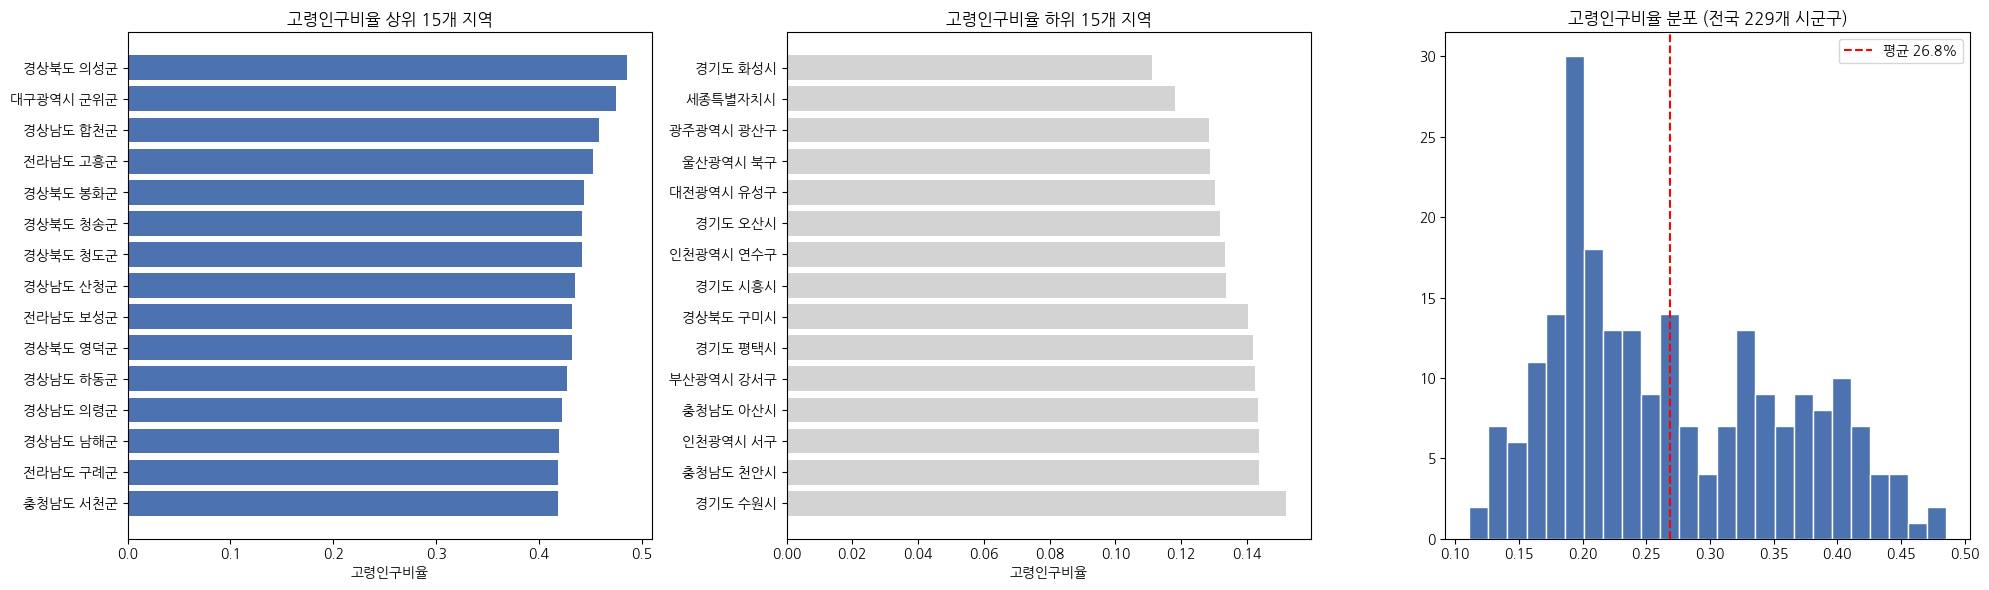

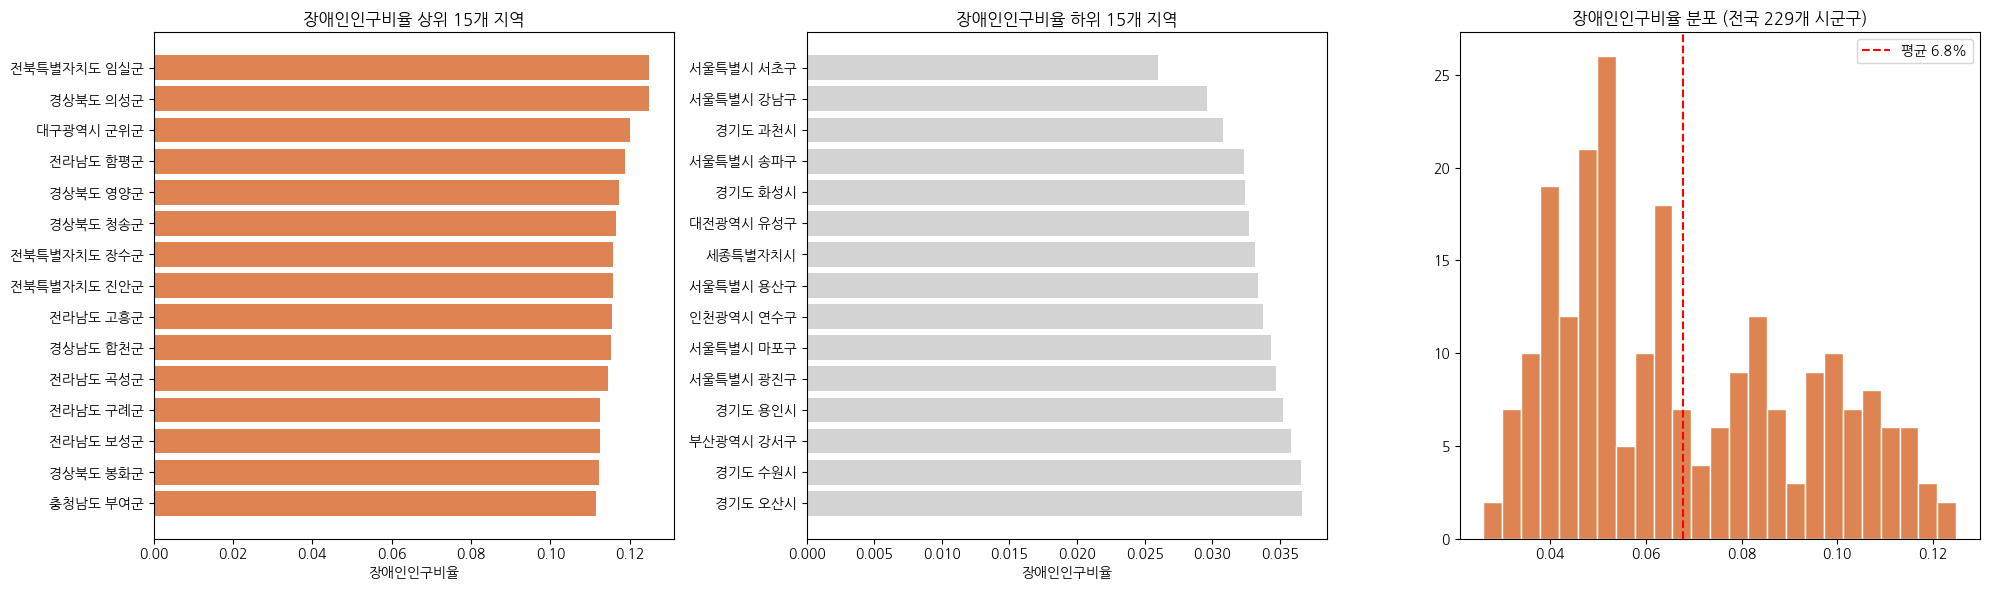

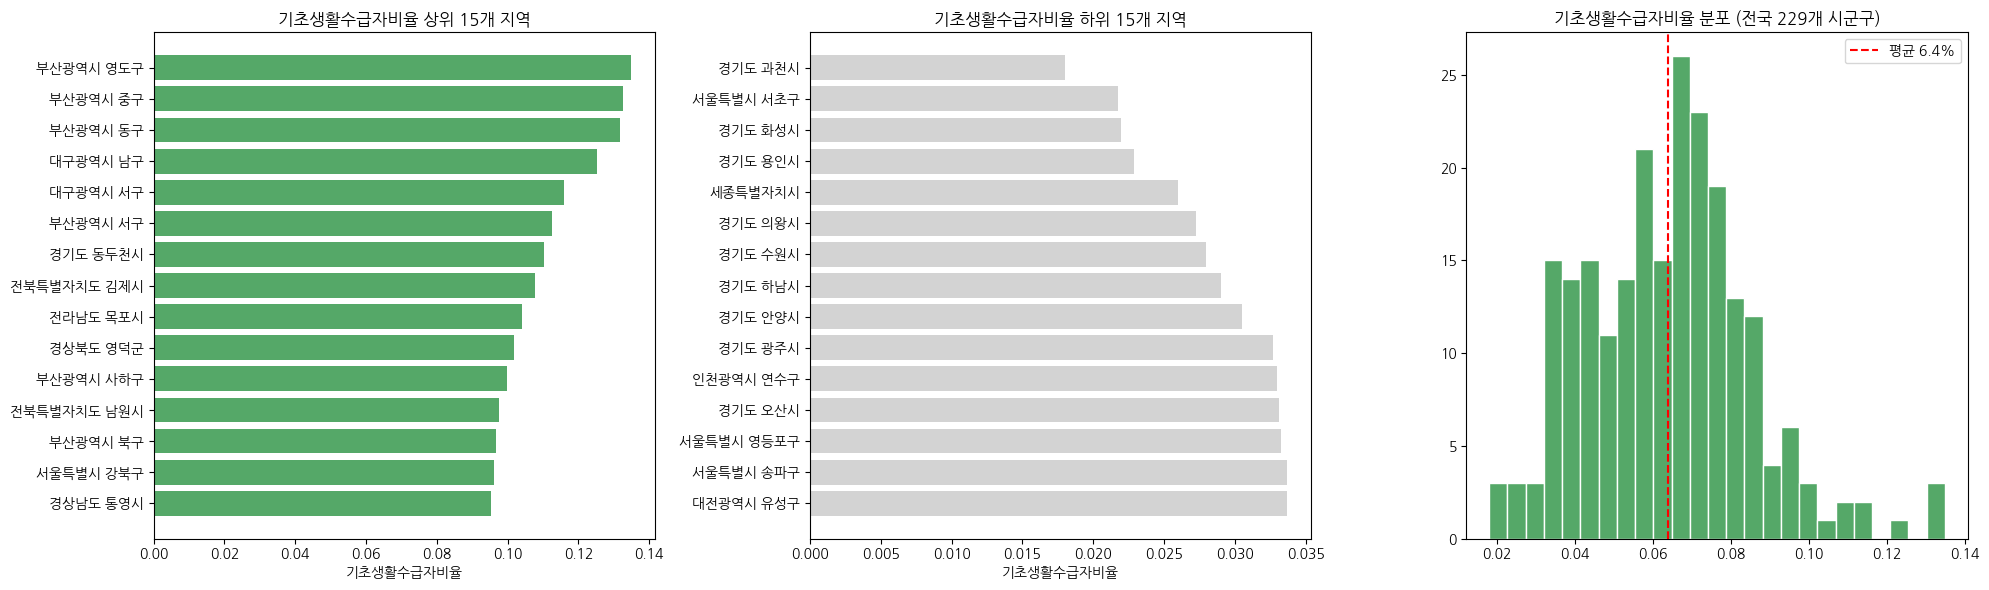

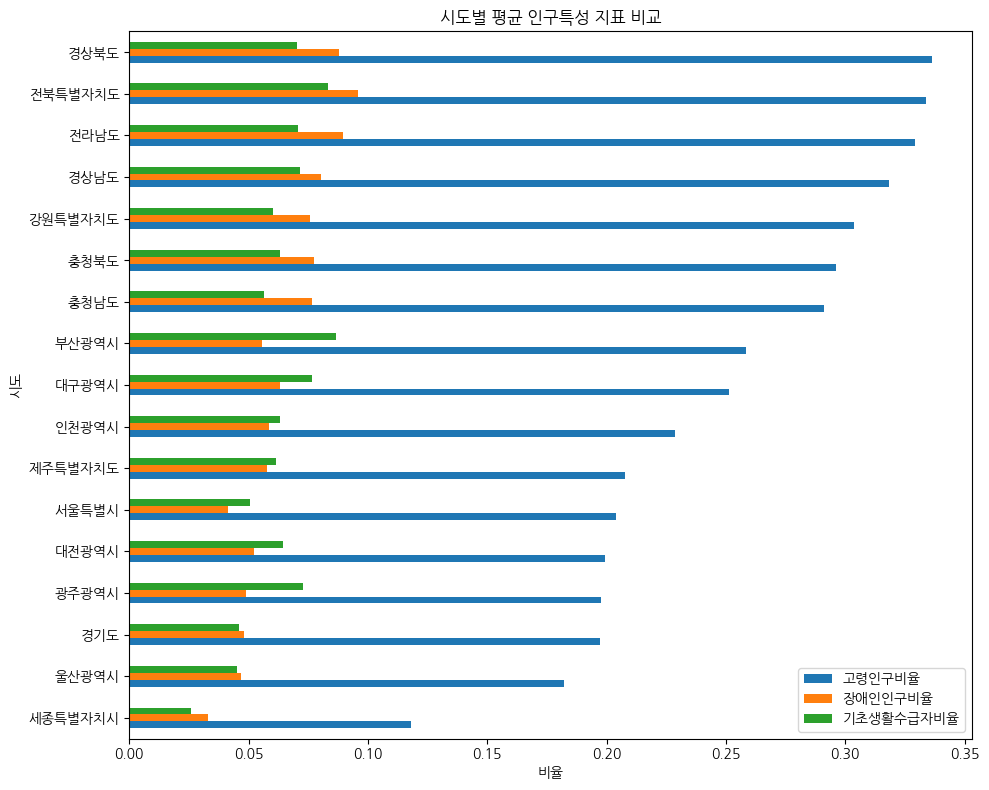

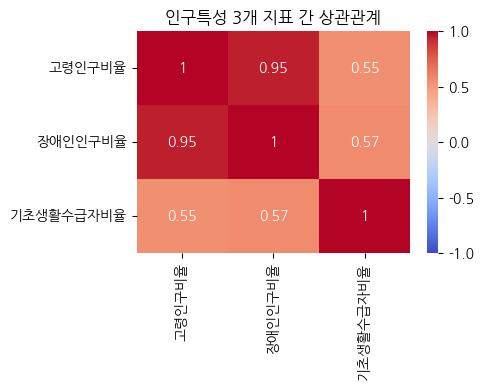

In [10]:
def plot_ratio(df, col, title, color):
    top = df.nlargest(15, col).sort_values(col)
    bottom = df.nsmallest(15, col).sort_values(col, ascending=False)

    fig, axes = plt.subplots(1, 3, figsize=(20, 6))

    # (1) 상위 15개 지역
    axes[0].barh(top['sigungu'], top[col], color=color)
    axes[0].set_title(f'{title} 상위 15개 지역')
    axes[0].set_xlabel(title)

    # (2) 하위 15개 지역
    axes[1].barh(bottom['sigungu'], bottom[col], color='lightgray')
    axes[1].set_title(f'{title} 하위 15개 지역')
    axes[1].set_xlabel(title)

    # (3) 전체 분포 히스토그램
    axes[2].hist(df[col], bins=25, color=color, edgecolor='white')
    axes[2].axvline(df[col].mean(), color='red', linestyle='--', label=f'평균 {df[col].mean():.1%}')
    axes[2].set_title(f'{title} 분포 (전국 229개 시군구)')
    axes[2].legend()

    plt.tight_layout()
    plt.savefig(f'{title}.png', dpi=150, bbox_inches='tight')
    plt.show()

plot_ratio(merged, '고령인구비율', '고령인구비율', '#4C72B0')
plot_ratio(merged, '장애인인구비율', '장애인인구비율', '#DD8452')
plot_ratio(merged, '기초생활수급자비율', '기초생활수급자비율', '#55A868')

# 시도별 평균 비교 (수도권 vs 비수도권, 도시 vs 농촌 맥락 파악용)
sido_avg = merged.groupby('시도')[['고령인구비율', '장애인인구비율', '기초생활수급자비율']].mean()
sido_avg = sido_avg.sort_values('고령인구비율', ascending=True)

fig, ax = plt.subplots(figsize=(10, 8))
sido_avg.plot(kind='barh', ax=ax)
ax.set_title('시도별 평균 인구특성 지표 비교')
ax.set_xlabel('비율')
plt.tight_layout()
plt.savefig('시도별_평균비교.png', dpi=150, bbox_inches='tight')
plt.show()

# 3개 지표 간 상관관계 (index 가중치 설계에 참고용 — 아래 설명 참고)
import seaborn as sns
corr = merged[['고령인구비율', '장애인인구비율', '기초생활수급자비율']].corr()
plt.figure(figsize=(5, 4))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('인구특성 3개 지표 간 상관관계')
plt.tight_layout()
plt.savefig('상관관계.png', dpi=150, bbox_inches='tight')
plt.show()